# Beer Reviews: Rankings, Rating Drivers, and Sentiment Analysis

Analysis of about 529,000 beer reviews (1998 to 2012) to find the strongest breweries, the highest-rated years, the factors that drive ratings, the best beers to recommend, and the favorite styles in written reviews.

`Python` · `Pandas` · `NumPy` · `Seaborn` / `Matplotlib` · `scikit-learn` · `NLTK (VADER)`


## Questions answered

- **Q1:** Which 3 breweries produce the strongest beers?
- **Q2:** In which year did beers receive the highest ratings?
- **Q3:** Which of taste, aroma, appearance, and palette matter most for the overall rating?
- **Q4:** Which 3 beers would I recommend, based on the data?
- **Q5:** Which style is the favorite in written reviews, and how does review sentiment compare to the overall score?

## Approach

- **Cleaning and exploration:** duplicates, missing values, timestamps, and rating distributions
- **Q1 and Q2:** group-level averages with minimum-sample thresholds, plus confidence intervals for the year comparison
- **Q3:** correlation analysis cross-checked with a standardized regression
- **Q4:** beers ranked by average rating (minimum 100 reviews), cross-checked with an aroma/taste score
- **Q5:** VADER sentiment scoring of every review, compared with numeric ratings by style, with a check for review-length effects

## Key results

- **Strongest beers:** Brewer 6513 (Schorschbräu), averaging 24.7% ABV, driven by extreme releases such as a 57.7% beer
- **Best year:** 2009 and 2010 are statistically tied for the highest ratings (about 3.87)
- **Rating drivers:** Aroma matters most, then taste. Appearance and palette add almost nothing once those two are known
- **Recommended beers:** Citra DIPA, Cantillon Blåbær Lambik, Heady Topper
- **Favorite style:** Gueuze by rating (tied with Berliner Weissbier); written sentiment and ratings agree strongly at the style level (Spearman 0.74)

## Setup and Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.linear_model import LinearRegression
from tqdm.auto import tqdm
from pathlib import Path

sns.set_theme(style='whitegrid', rc={'axes.grid.axis': 'y'}) # Horizontal grid lines only
tqdm.pandas()

df = pd.read_csv(r'C:\Users\lewis\Downloads\datasets\BeerDataScienceProject.tar.bz2', compression='bz2')
df.columns = df.columns.str.lower()
df.head()

,beer_abv,beer_beerid,beer_brewerid,beer_name,beer_style,review_appearance,review_palette,review_overall,review_taste,review_profilename,review_aroma,review_text,review_time
0,5.0,47986,10325,Sausa Weizen,Hefeweizen,2.5,2.0,1.5,1.5,stcules,1.5,A lot of foam. But a lot. In the smell some ba...,1234817823
1,6.2,48213,10325,Red Moon,English Strong Ale,3.0,2.5,3.0,3.0,stcules,3.0,"Dark red color, light beige foam, average. In ...",1235915097
2,6.5,48215,10325,Black Horse Black Beer,Foreign / Export Stout,3.0,2.5,3.0,3.0,stcules,3.0,"Almost totally black. Beige foam, quite compac...",1235916604
3,5.0,47969,10325,Sausa Pils,German Pilsener,3.5,3.0,3.0,2.5,stcules,3.0,"Golden yellow color. White, compact foam, quit...",1234725145
4,7.7,64883,1075,Cauldron DIPA,American Double / Imperial IPA,4.0,4.5,4.0,4.0,johnmichaelsen,4.5,"According to the website, the style for the Ca...",1293735206


## Data Cleaning

In [2]:
# Drop exact duplicate rows
n_before = len(df)
df = df.drop_duplicates().copy()
print(f'Dropped {n_before - len(df)} duplicate rows')

Dropped 0 duplicate rows


In [3]:
# Convert timestamp to datetime and extract the year
df['review_datetime'] = pd.to_datetime(df['review_time'], unit='s')
df['review_year'] = df['review_datetime'].dt.year

In [4]:
# Missing ABV is left as-is; Q1 drops those rows for the ABV ranking only
print('Missing ABV:', df['beer_abv'].isna().sum())

Missing ABV: 20280


**Cleaning notes**
- No exact duplicate rows were found
- 20,280 reviews (3.8%) have no ABV: kept for rating analyses and excluded only from Q1
- 119 reviews have no text: kept for rating analyses and excluded only from Q5 sentiment scoring
- 115 reviews have no profile name, which no question uses, so I left them as-is

## Data Exploration

Check size, data types, missing values, ratings distributions, and review volume by year and style.

In [5]:
df.shape

(528870, 15)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 528870 entries, 0 to 528869
Data columns (total 15 columns):
 #   Column              Non-Null Count   Dtype        
---  ------              --------------   -----        
 0   beer_abv            508590 non-null  float64      
 1   beer_beerid         528870 non-null  int64        
 2   beer_brewerid       528870 non-null  int64        
 3   beer_name           528870 non-null  str          
 4   beer_style          528870 non-null  str          
 5   review_appearance   528870 non-null  float64      
 6   review_palette      528870 non-null  float64      
 7   review_overall      528870 non-null  float64      
 8   review_taste        528870 non-null  float64      
 9   review_profilename  528755 non-null  str          
 10  review_aroma        528870 non-null  float64      
 11  review_text         528751 non-null  str          
 12  review_time         528870 non-null  int64        
 13  review_datetime     528870 non-null  datetime64[s]
 14 

In [7]:
df.isna().sum()

beer_abv              20280
beer_beerid               0
beer_brewerid             0
beer_name                 0
beer_style                0
review_appearance         0
review_palette            0
review_overall            0
review_taste              0
review_profilename      115
review_aroma              0
review_text             119
review_time               0
review_datetime           0
review_year               0
dtype: int64

In [8]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
beer_abv,508590.0,7.017442,0.01,5.3,6.5,8.5,57.7,2.20446
beer_beerid,528870.0,22098.466016,3.0,1745.0,14368.0,40528.0,77310.0,22158.284352
beer_brewerid,528870.0,2598.423429,1.0,132.0,394.0,1475.0,27980.0,5281.80535
review_appearance,528870.0,3.864522,0.0,3.5,4.0,4.0,5.0,0.60401
review_palette,528870.0,3.758926,1.0,3.5,4.0,4.0,5.0,0.685335
review_overall,528870.0,3.833197,0.0,3.5,4.0,4.5,5.0,0.709962
review_taste,528870.0,3.765993,1.0,3.5,4.0,4.0,5.0,0.669018
review_aroma,528870.0,3.81735,1.0,3.5,4.0,4.5,5.0,0.718903
review_time,528870.0,1224884554.953119,884390401.0,1174612672.25,1240366263.0,1288559535.5,1326276656.0,76056004.270479
review_datetime,528870,2008-10-24 21:42:34,1998-01-10 00:00:01,2007-03-23 01:17:52,2009-04-22 02:11:03,2010-10-31 21:12:15,2012-01-11 10:10:56,NaN


In [9]:
print('Unique beers:     ', df['beer_beerid'].nunique())
print('Unique breweries: ', df['beer_brewerid'].nunique())
print('Unique styles:    ', df['beer_style'].nunique())
print('Unique reviewers: ', df['review_profilename'].nunique())

Unique beers:      20200
Unique breweries:  1803
Unique styles:     104
Unique reviewers:  22800


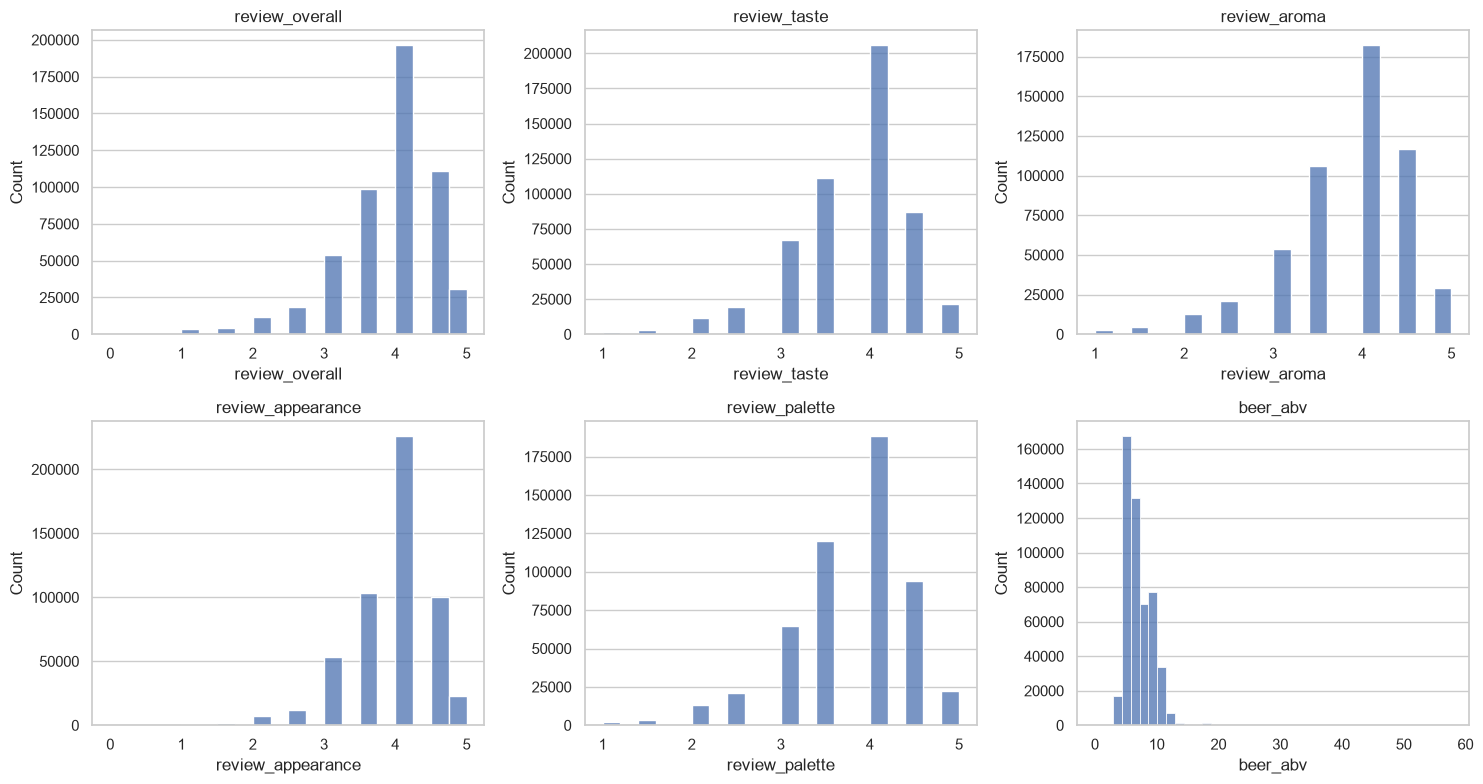

In [10]:
rating_cols = ['review_overall', 'review_taste', 'review_aroma',
               'review_appearance', 'review_palette']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, rating_cols):
    sns.histplot(df[col], bins=20, ax=ax)
    ax.set_title(col)

# Use the spare panel for ABV
sns.histplot(df['beer_abv'].dropna(), bins=40, ax=axes.flat[5])
axes.flat[5].set_title('beer_abv')

plt.tight_layout()
plt.show()

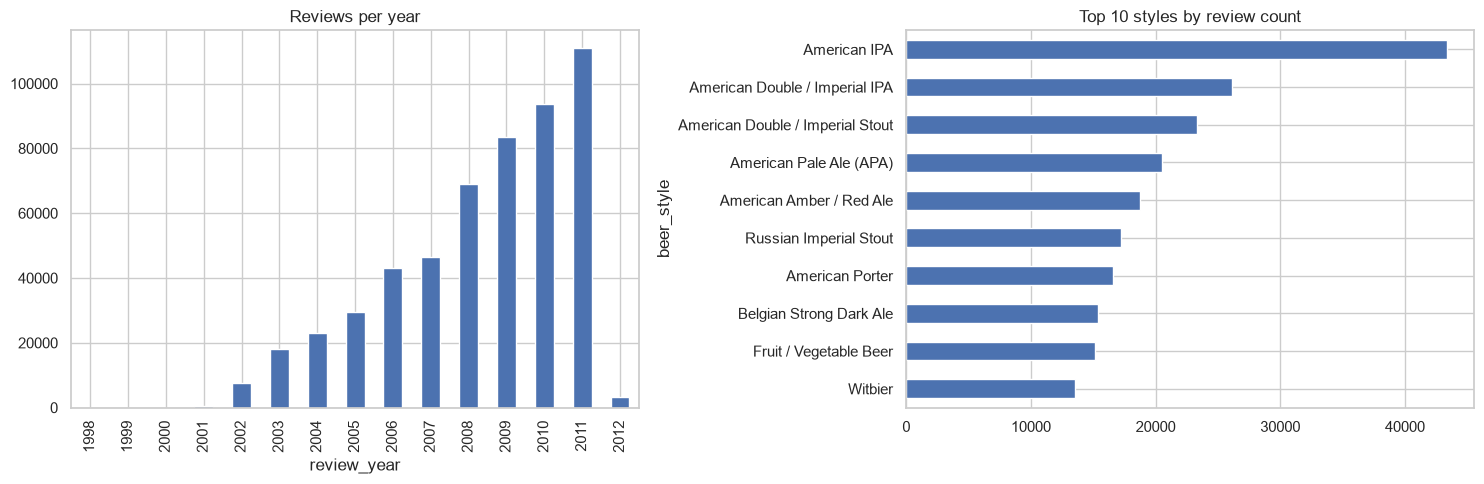

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

df['review_year'].value_counts().sort_index().plot(kind='bar', ax=axes[0])
axes[0].set_title('Reviews per year')

df['beer_style'].value_counts().head(10).plot(kind='barh', ax=axes[1])
axes[1].invert_yaxis()
axes[1].set_title('Top 10 styles by review count')

plt.tight_layout()
plt.show()

## Q1: Breweries with the strongest beers

Which 3 breweries produce the strongest beers? I measure strength as each brewer's average ABV across its beers, counting each beer once so heavily reviewed beers don't dominate. Only brewers with at least 5 beers are ranked, so a brewer with one or two beers can't win by chance.

In [12]:
# One row per beer so review counts don't weight the average
beers = (df.dropna(subset=['beer_abv'])
           .drop_duplicates(subset='beer_beerid')
           [['beer_beerid', 'beer_brewerid', 'beer_name', 'beer_abv']])

brewer_abv = (beers.groupby('beer_brewerid')
                   .agg(avg_abv=('beer_abv', 'mean'),
                        median_abv=('beer_abv', 'median'),
                        max_abv=('beer_abv', 'max'),
                        n_beers=('beer_beerid', 'count')))

# Require several beers so a one-beer brewery doesn't win on a fluke
eligible_brewers = brewer_abv[brewer_abv['n_beers'] >= 5].sort_values('avg_abv', ascending=False)
top_brewers = eligible_brewers.head(3)
eligible_brewers.head(5).round(2)

,avg_abv,median_abv,max_abv,n_beers
beer_brewerid,,,,
6513,24.69,16.00,57.7,10
396,10.17,11.00,12.0,52
22202,9.68,8.65,15.0,10
881,9.63,9.00,12.2,6
2958,9.25,8.00,19.5,30


In [13]:
# Inspect the beers behind the top brewer
(beers[beers['beer_brewerid'] == 6513]
     .sort_values('beer_abv', ascending=False))

,beer_beerid,beer_brewerid,beer_name,beer_abv
12889,73368,6513,Schorschbräu Schorschbock 57%,57.70
12909,57856,6513,Schorschbräu Schorschbock 43%,43.00
12911,55712,6513,Schorschbräu Schorschbock 40%,39.44
12888,51466,6513,Schorschbräu Schorschbock 31%,30.86
12882,47421,6513,Schorschbock,16.00
12887,71004,6513,Schorsch Weizen 16%,16.00
12899,20169,6513,Schorschbräu Donner Weizen,13.00
12881,73357,6513,Schorschbock Ice 13,13.00
12890,15578,6513,Schorschbräu Donner Bock,13.00
12880,32973,6513,Schorschbräu Dunkles,4.90


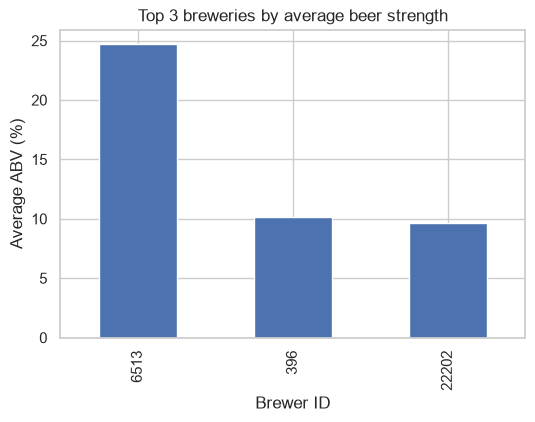

In [40]:
top_brewers['avg_abv'].plot(kind='bar', figsize=(6, 4))
plt.ylabel('Average ABV (%)')
plt.xlabel('Brewer ID')
plt.title('Top 3 breweries by average beer strength')
plt.show()

### Q1 findings

- **Strongest overall:** Brewer 6513 (Schorschbräu), averaging 24.7% ABV across 10 beers
- **Why it's an outlier:** A few extreme releases, including a 57.7% Schorschbock, pull the average up. Its median beer is only 16% ABV
- **Data check:** The extreme beers are real products, not data errors, so I kept them
- **Strongest on consistent output:** Brewer 396, averaging 10.2% ABV across 52 beers
- **Third place:** Brewer 22202, at 9.7%

**Method notes**
- ABV was averaged at the beer level so heavily reviewed beers don't outweigh the rest of a brewer's lineup
- Only brewers with at least 5 beers were ranked
- Rows with missing ABV were excluded from this question
- Breweries are identified by ID because the dataset has no brewery names

## Q2: Year with the highest ratings

In which year did beers receive the highest ratings? I compare the mean overall rating by year alongside review counts, since the earliest years have very few reviews and their averages are unreliable. Confidence intervals then show whether the top years are genuinely different from each other.

In [15]:
yearly = (df.groupby('review_year')['review_overall']
            .agg(['mean', 'count'])
            .round(3))
yearly

,mean,count
review_year,,
1998,3.891,23
1999,4.000,25
2000,4.182,33
2001,3.928,602
2002,3.799,7581
2003,3.753,18187
2004,3.795,22905
2005,3.832,29433
2006,3.798,43083


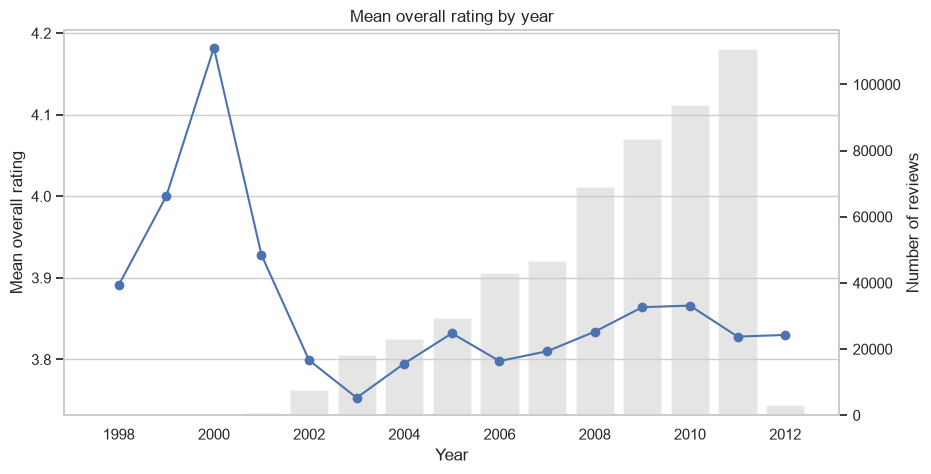

In [16]:
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(yearly.index, yearly['mean'], marker='o')
ax1.set_ylabel('Mean overall rating')
ax1.set_xlabel('Year')

ax2 = ax1.twinx()
ax2.bar(yearly.index, yearly['count'], alpha=0.2, color='gray')
ax2.set_ylabel('Number of reviews')

# Turn off the second axis grid and the vertical lines to avoid clutter
ax2.grid(False)
ax1.grid(axis='x', visible=False)

# Keep the line on top of the bars
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)

plt.title('Mean overall rating by year')
plt.show()

In [17]:
# Confidence interval for each year's mean rating
stats = df.groupby('review_year')['review_overall'].agg(['mean', 'std', 'count'])
stats['se'] = stats['std'] / np.sqrt(stats['count'])
stats['ci_low'] = stats['mean'] - 1.96 * stats['se']
stats['ci_high'] = stats['mean'] + 1.96 * stats['se']

# Only years with a reasonable sample
stats[stats['count'] >= 1000].sort_values('mean', ascending=False).round(3)

,mean,std,count,se,ci_low,ci_high
review_year,,,,,,
2010,3.866,0.697,93810,0.002,3.862,3.871
2009,3.864,0.698,83578,0.002,3.860,3.869
2008,3.834,0.711,69080,0.003,3.829,3.839
2005,3.832,0.744,29433,0.004,3.824,3.841
2012,3.830,0.645,3180,0.011,3.807,3.852
2011,3.828,0.664,110836,0.002,3.824,3.832
2007,3.810,0.730,46514,0.003,3.803,3.816
2002,3.799,0.805,7581,0.009,3.781,3.817
2006,3.798,0.751,43083,0.004,3.791,3.805


In [18]:
# Confidence interval for the difference between the top two years
a = df.loc[df['review_year'] == 2010, 'review_overall']
b = df.loc[df['review_year'] == 2009, 'review_overall']

diff = a.mean() - b.mean()
se_diff = np.sqrt(a.var() / len(a) + b.var() / len(b))
print(f'Difference: {diff:.3f}, 95% CI: [{diff - 1.96 * se_diff:.3f}, {diff + 1.96 * se_diff:.3f}]')

Difference: 0.002, 95% CI: [-0.005, 0.008]


### Q2 findings

- **Highest-rated years:** 2010 (mean 3.866) and 2009 (3.864) are statistically tied. The difference of 0.002 has a 95% confidence interval of [-0.005, 0.008]
- **Both stand above later years:** Their intervals sit above 2008 (3.834) and every year after it
- **Raw peak is noise:** 2000 has the top mean (4.18) but only 33 reviews, as do 1998, 1999, and 2001, so I limited the comparison to years with at least 1,000 reviews
- **Small differences overall:** Yearly means from 2002 onward stay between 3.75 and 3.87, so no year stands out dramatically
- **2012 caveat:** Only 3,180 reviews, so it is likely a partial year

## Q3: Which factors matter most for the overall rating

Which of taste, aroma, appearance, and palette matter most for the overall rating? I start with each factor's correlation with the overall score, then fit a regression on standardized ratings to see each factor's effect with the others held fixed, since the four ratings are correlated with one another.

In [19]:
factors = ['review_taste', 'review_aroma', 'review_appearance', 'review_palette']

# Correlation of each factor with the overall rating
corr_overall = (df[factors + ['review_overall']]
                  .corr()['review_overall']
                  .drop('review_overall')
                  .sort_values(ascending=False))
corr_overall.round(3)

review_aroma         0.783
review_taste         0.692
review_palette       0.602
review_appearance    0.487
Name: review_overall, dtype: float64

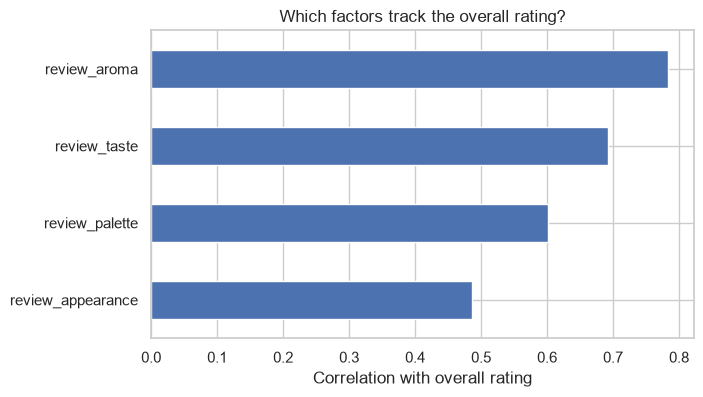

In [20]:
corr_overall.plot(kind='barh', figsize=(7, 4))
plt.gca().invert_yaxis()
plt.xlabel('Correlation with overall rating')
plt.title('Which factors track the overall rating?')
plt.show()

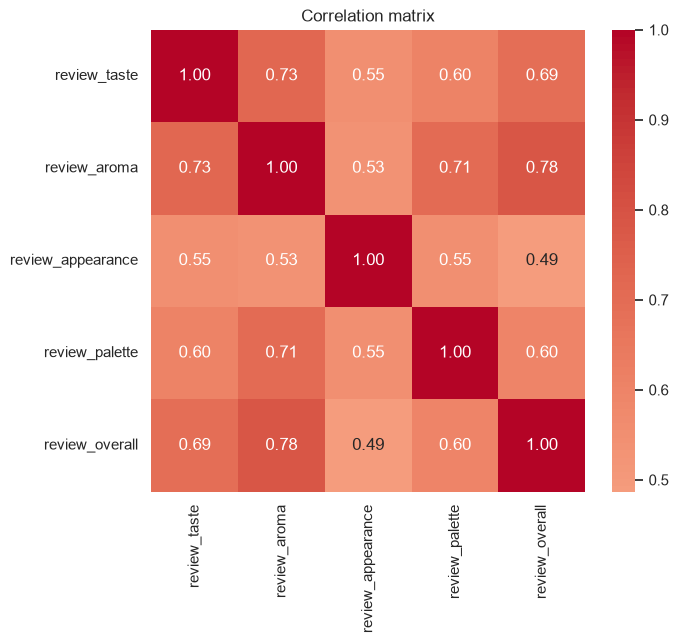

In [21]:
# Heatmap including the factors' correlation with each other
plt.figure(figsize=(7, 6))
sns.heatmap(df[factors + ['review_overall']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix')
plt.show()

In [22]:
data = df[factors + ['review_overall']].dropna()
x = (data[factors] - data[factors].mean()) / data[factors].std()
y = data['review_overall']

model = LinearRegression().fit(x, y)
pd.Series(model.coef_, index=factors).sort_values(ascending=False).round(3)

review_aroma         0.398
review_taste         0.174
review_palette       0.031
review_appearance    0.020
dtype: float64

### Q3 findings

- **Most important factor:** Aroma, with the highest correlation (0.78) and the largest standardized regression coefficient (0.40)
- **Second:** Taste (correlation 0.69, coefficient 0.17)
- **Palette and appearance:** Correlate with the overall score (0.60 and 0.49) but add almost nothing once aroma and taste are held fixed (coefficients 0.03 and 0.02)
- **Why the two methods differ:** A beer that looks good usually also smells and tastes good, so palette and appearance mostly reflect the same signal
- **Takeaway:** Correlation alone suggests all four factors matter, but the regression shows two carry nearly all of it

## Q4: Three beers to recommend

Ranking by mean rating alone favors beers with a handful of perfect reviews, so I required a minimum review count. Beers are grouped by beer ID because names can repeat across breweries.

In [23]:
beer_stats = (df.groupby('beer_beerid')
                .agg(beer_name=('beer_name', 'first'),
                     beer_style=('beer_style', 'first'),
                     avg_overall=('review_overall', 'mean'),
                     avg_aroma=('review_aroma', 'mean'),
                     avg_taste=('review_taste', 'mean'),
                     n_reviews=('review_overall', 'count')))

# Only beers with enough reviews to trust the average
min_reviews = 100
top_beers = (beer_stats[beer_stats['n_reviews'] >= min_reviews]
             .sort_values('avg_overall', ascending=False)
             .head(10)
             .round(3))
top_beers

,beer_name,beer_style,avg_overall,avg_aroma,avg_taste,n_reviews
beer_beerid,,,,,,
56082,Citra DIPA,American Double / Imperial IPA,4.631,4.573,4.373,252
36316,Cantillon Blåbær Lambik,Lambic - Fruit,4.628,4.628,4.494,156
16814,Heady Topper,American Double / Imperial IPA,4.626,4.609,4.405,469
47658,Founders CBS Imperial Stout,American Double / Imperial Stout,4.591,4.697,4.579,637
6368,Masala Mama India Pale Ale,American IPA,4.489,4.397,4.332,662
44942,Unplugged Bohemian Lager,Czech Pilsener,4.439,4.237,4.147,139
2899,Andechser Doppelbock Dunkel,Doppelbock,4.432,4.436,4.362,287
20578,Czar Jack Imperial Stout,Russian Imperial Stout,4.424,4.487,4.387,119
13826,Cantillon Lou Pepe - Gueuze,Gueuze,4.406,4.379,4.230,128


Since Q3 showed that aroma and taste drive the overall score, I also ranked beers on those two alone to check that the top picks hold up under both.

In [24]:
# Weighted score using the regression findings (aroma counts most)
eligible = beer_stats[beer_stats['n_reviews'] >= min_reviews].copy()
eligible['weighted_score'] = 0.7 * eligible['avg_aroma'] + 0.3 * eligible['avg_taste']

eligible.sort_values('weighted_score', ascending=False).head(10).round(3)

,beer_name,beer_style,avg_overall,avg_aroma,avg_taste,n_reviews,weighted_score
beer_beerid,,,,,,,
47658,Founders CBS Imperial Stout,American Double / Imperial Stout,4.591,4.697,4.579,637,4.662
36316,Cantillon Blåbær Lambik,Lambic - Fruit,4.628,4.628,4.494,156,4.588
19960,Founders KBS (Kentucky Breakfast Stout),American Double / Imperial Stout,4.398,4.626,4.480,1932,4.582
47022,Hunahpu's Imperial Stout,American Double / Imperial Stout,4.366,4.564,4.512,429,4.548
16814,Heady Topper,American Double / Imperial IPA,4.626,4.609,4.405,469,4.548
56082,Citra DIPA,American Double / Imperial IPA,4.631,4.573,4.373,252,4.513
645,Trappistes Rochefort 10,Quadrupel (Quad),4.339,4.544,4.431,2170,4.510
51257,Black Tuesday,American Double / Imperial Stout,4.210,4.510,4.400,381,4.477
11757,Founders Breakfast Stout,American Double / Imperial Stout,4.355,4.501,4.388,2502,4.467


### Q4 findings

**Top 3 recommendations** (beers with at least 100 reviews):

1. **Citra DIPA:** 4.63 average overall rating (252 reviews)
2. **Cantillon Blåbær Lambik:** 4.62 (156 reviews)
3. **Heady Topper:** 4.62 (469 reviews)

- **Why these three:** They rank highest by overall rating and also appear in the top 5 when scored on aroma and taste alone (the two factors that matter most in Q3)
- **Weighting note:** The aroma/taste ranking uses a 0.7/0.3 weighting, a judgment call loosely based on the regression coefficients

**Honorable mention: Founders CBS Imperial Stout**
- Ranks first on the aroma-and-taste score but outside the top 10 on overall rating
- Suggests reviewers weigh other qualities too, consistent with the Q3 regression where aroma and taste explained most but not all of the overall score

**Audience note**
- Cantillon Blåbær is a fruited sour lambic, so it's a strong pick by the data but a riskier recommendation for a friend whose tastes I don't know

## Q5: Favorite style, written reviews vs. numeric ratings

Which beer style is the favorite in written reviews, and how do the reviews compare to the numeric scores? I score the text of every review with VADER sentiment analysis, average the scores by style, and compare that ranking to the ranking by overall rating.

### How VADER works

- VADER is a rule-based sentiment tool built for informal text such as reviews
- Each word has a sentiment score in a built-in dictionary, adjusted for negation ("not good"), intensifiers ("very good"), and punctuation
- Each review gets a **compound score** from -1 (most negative) to +1 (most positive)

In [25]:
nltk.download('vader_lexicon', quiet=True)
sia = SentimentIntensityAnalyzer()

# Quick sanity check on a few reviews
for text in df['review_text'].dropna().head(3):
    print(sia.polarity_scores(text)['compound'], '|', text[:100])

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\lewis\AppData\Roaming\nltk_data...


0.1879 | A lot of foam. But a lot. In the smell some banana, and then lactic and tart. Not a good start. Quit
0.5927 | Dark red color, light beige foam, average. In the smell malt and caramel, not really light. Again ma
0.3021 | Almost totally black. Beige foam, quite compact, not bad. Light smell, just a bit of roast, and some


[nltk_data]   Package vader_lexicon is already up-to-date!


In [26]:
cache = Path('scored_reviews.pkl')

if cache.exists():
    # Load previously scored reviews
    scored = pd.read_pickle(cache)
else:
    # Score all reviews with text (about 15 minutes)
    scored = df.dropna(subset=['review_text']).copy()
    scored['sentiment'] = scored['review_text'].progress_apply(
        lambda t: sia.polarity_scores(t)['compound'])
    scored = scored[['beer_beerid', 'beer_style', 'review_overall', 'review_text', 'sentiment']]
    scored.to_pickle(cache)

### Comparing styles: sentiment vs. rating

In [27]:
# Flag strongly positive reviews as a measure that isn't stuck at the ceiling
scored['very_positive'] = scored['sentiment'] >= 0.95

# Review length, to check whether it drives the scores
scored['n_words'] = scored['review_text'].str.split().str.len()

style_stats = (scored.groupby('beer_style')
                     .agg(mean_sentiment=('sentiment', 'mean'),
                          median_sentiment=('sentiment', 'median'),
                          pct_very_positive=('very_positive', 'mean'),
                          mean_overall=('review_overall', 'mean'),
                          n_reviews=('sentiment', 'count')))

# Only styles with enough reviews to be stable
style_stats = style_stats[style_stats['n_reviews'] >= 500].copy()

style_stats['rank_sentiment'] = style_stats['mean_sentiment'].rank(ascending=False)
style_stats['rank_overall'] = style_stats['mean_overall'].rank(ascending=False)

style_stats.sort_values('rank_sentiment').head(10).round(3)

,mean_sentiment,median_sentiment,pct_very_positive,mean_overall,n_reviews,rank_sentiment,rank_overall
beer_style,,,,,,,
Quadrupel (Quad),0.858,0.956,0.537,4.049,4933,1.0,7.0
Dortmunder / Export Lager,0.852,0.953,0.519,4.052,1809,2.0,6.0
Flanders Red Ale,0.849,0.952,0.514,3.962,2856,3.0,16.0
American Double / Imperial Stout,0.848,0.959,0.556,4.100,23352,4.0,3.0
Wheatwine,0.843,0.960,0.559,3.817,891,5.0,50.0
Belgian Strong Dark Ale,0.833,0.945,0.476,4.009,15403,6.0,11.0
Old Ale,0.831,0.951,0.506,3.865,4817,7.0,36.0
Rye Beer,0.830,0.947,0.484,4.070,5179,8.0,5.0
Rauchbier,0.830,0.947,0.487,3.807,2607,9.0,55.0


In [28]:
# Top styles by numeric rating, to name the favorite on that measure
style_stats.sort_values('rank_overall').head(10)[['mean_overall', 'mean_sentiment', 'n_reviews', 'rank_overall', 'rank_sentiment']].round(3)

,mean_overall,mean_sentiment,n_reviews,rank_overall,rank_sentiment
beer_style,,,,,
Gueuze,4.141,0.793,1575,1.0,26.0
Berliner Weissbier,4.134,0.829,933,2.0,10.0
American Double / Imperial Stout,4.100,0.848,23352,3.0,4.0
Oatmeal Stout,4.081,0.806,6720,4.0,18.0
Rye Beer,4.070,0.830,5179,5.0,8.0
Dortmunder / Export Lager,4.052,0.852,1809,6.0,2.0
Quadrupel (Quad),4.049,0.858,4933,7.0,1.0
Lambic - Fruit,4.027,0.825,3768,8.0,11.0
Russian Imperial Stout,4.026,0.810,17183,9.0,17.0


In [29]:
# Confidence intervals for the top styles by rating
top_styles = style_stats.sort_values('rank_overall').head(5).index

ci = (scored[scored['beer_style'].isin(top_styles)]
        .groupby('beer_style')['review_overall']
        .agg(['mean', 'std', 'count']))
ci['se'] = ci['std'] / np.sqrt(ci['count'])
ci['ci_low'] = ci['mean'] - 1.96 * ci['se']
ci['ci_high'] = ci['mean'] + 1.96 * ci['se']

ci.sort_values('mean', ascending=False).round(3)

,mean,std,count,se,ci_low,ci_high
beer_style,,,,,,
Gueuze,4.141,0.658,1575,0.017,4.108,4.173
Berliner Weissbier,4.134,0.676,933,0.022,4.091,4.177
American Double / Imperial Stout,4.100,0.645,23352,0.004,4.092,4.109
Oatmeal Stout,4.081,0.594,6720,0.007,4.067,4.095
Rye Beer,4.070,0.570,5179,0.008,4.054,4.086


### Is Gueuze's lead over Berliner Weissbier real?

In [30]:
# Confidence interval for the difference between the top two styles
a = scored.loc[scored['beer_style'] == 'Gueuze', 'review_overall']
b = scored.loc[scored['beer_style'] == 'Berliner Weissbier', 'review_overall']

diff = a.mean() - b.mean()
se_diff = np.sqrt(a.var() / len(a) + b.var() / len(b))
print(f'Difference: {diff:.3f}, 95% CI: [{diff - 1.96 * se_diff:.3f}, {diff + 1.96 * se_diff:.3f}]')

Difference: 0.007, 95% CI: [-0.047, 0.061]


In [31]:
# How similar are the two rankings? (1.0 = identical order)
print('Spearman rank correlation:',
      round(style_stats['rank_sentiment'].corr(style_stats['rank_overall'], method='spearman'), 3))

# Biggest disagreements between the two rankings
style_stats['rank_gap'] = style_stats['rank_sentiment'] - style_stats['rank_overall']
style_stats.sort_values('rank_gap')[['mean_sentiment', 'mean_overall', 'rank_sentiment', 'rank_overall', 'rank_gap']].round(3).iloc[[0, 1, 2, -3, -2, -1]]

Spearman rank correlation: 0.74


,mean_sentiment,mean_overall,rank_sentiment,rank_overall,rank_gap
beer_style,,,,,
Rauchbier,0.830,3.807,9.0,55.0,-46.0
Wheatwine,0.843,3.817,5.0,50.0,-45.0
American Strong Ale,0.793,3.738,27.0,63.0,-36.0
American IPA,0.775,3.990,41.0,12.0,29.0
Keller Bier / Zwickel Bier,0.760,3.989,50.0,13.0,37.0
Lambic - Unblended,0.742,4.011,60.0,10.0,50.0


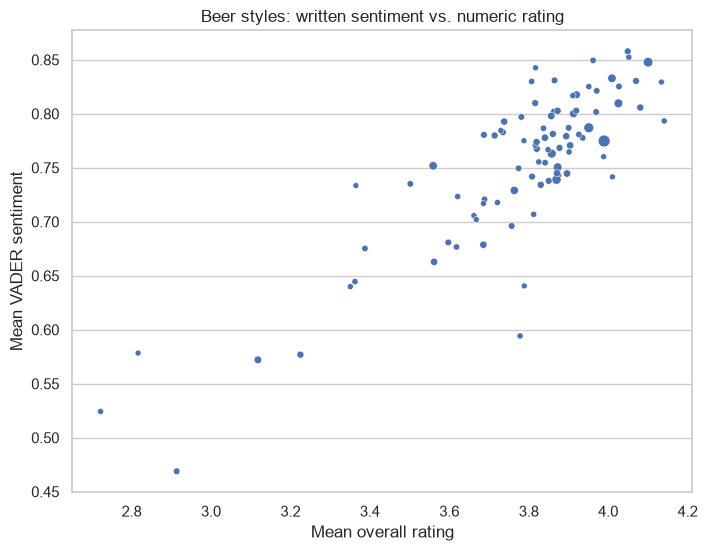

In [32]:
# Sentiment vs. rating, one point per style
plt.figure(figsize=(8, 6))
sns.scatterplot(data=style_stats, x='mean_overall', y='mean_sentiment', size='n_reviews', legend=False)
plt.xlabel('Mean overall rating')
plt.ylabel('Mean VADER sentiment')
plt.title('Beer styles: written sentiment vs. numeric rating')
plt.show()

### Does review length drive sentiment?

In [33]:
print('Correlation of sentiment with word count:',
      round(scored['n_words'].corr(scored['sentiment']), 3))

Correlation of sentiment with word count: 0.201


In [34]:
# Does the sentiment ranking survive after accounting for review length?
scored['length_bucket'] = pd.qcut(scored['n_words'], 4, labels=['short', 'medium', 'long', 'very_long'])

by_length = (scored.groupby(['beer_style', 'length_bucket'], observed=True)['sentiment']
                   .mean().unstack())

# Compare the gap styles with the overall pattern
by_length.loc[['Rauchbier', 'Wheatwine', 'Lambic - Unblended', 'American IPA']].round(3)

length_bucket,short,medium,long,very_long
beer_style,,,,
Rauchbier,0.698,0.792,0.858,0.925
Wheatwine,0.683,0.780,0.864,0.908
Lambic - Unblended,0.537,0.744,0.748,0.850
American IPA,0.664,0.746,0.808,0.875


In [35]:
# Average review length for the gap styles
(scored.groupby('beer_style')['n_words'].mean()
       .loc[['Rauchbier', 'Wheatwine', 'Lambic - Unblended', 'American IPA']].round(1))

beer_style
Rauchbier             129.1
Wheatwine             154.4
Lambic - Unblended    143.8
American IPA          124.3
Name: n_words, dtype: float64

In [36]:
# Length-adjusted sentiment: subtract each length bucket's mean
bucket_mean = scored.groupby('length_bucket', observed=True)['sentiment'].transform('mean')
scored['sentiment_adj'] = scored['sentiment'] - bucket_mean

style_stats['mean_sentiment_adj'] = scored.groupby('beer_style')['sentiment_adj'].mean()
style_stats['rank_sentiment_adj'] = style_stats['mean_sentiment_adj'].rank(ascending=False)

print('Spearman (adjusted sentiment vs. rating):',
      round(style_stats['rank_sentiment_adj'].corr(style_stats['rank_overall'], method='spearman'), 3))

# Gap styles plus Gueuze, before and after adjusting
style_stats.loc[['Rauchbier', 'Wheatwine', 'Lambic - Unblended', 'American IPA', 'Gueuze'],
                ['rank_sentiment', 'rank_sentiment_adj', 'rank_overall']]

Spearman (adjusted sentiment vs. rating): 0.73


,rank_sentiment,rank_sentiment_adj,rank_overall
beer_style,,,
Rauchbier,9.0,9.0,55.0
Wheatwine,5.0,14.0,50.0
Lambic - Unblended,60.0,70.0,10.0
American IPA,41.0,39.0,12.0
Gueuze,26.0,43.0,1.0


### Is sour-beer vocabulary being misread?

In [37]:
# Compare reviews that use typical sour-beer descriptors with those that don't
sour_words = ['sour', 'tart', 'funky', 'acidic', 'barnyard']
pattern = '|'.join(sour_words)

sours = scored[scored['beer_style'].isin(['Lambic - Unblended', 'Gueuze'])].copy()
sours['mentions_sour_terms'] = sours['review_text'].str.lower().str.contains(pattern)

sours.groupby('mentions_sour_terms').agg(
    mean_sentiment=('sentiment', 'mean'),
    mean_rating=('review_overall', 'mean'),
    mean_words=('n_words', 'mean'),
    n_reviews=('sentiment', 'count')).round(3)

,mean_sentiment,mean_rating,mean_words,n_reviews
mentions_sour_terms,,,,
False,0.657,3.839,110.696,112
True,0.784,4.114,145.133,2168


### Q5 findings

**Method**
- Scored every review with VADER's compound sentiment
- Compared style-level averages to the numeric overall rating
- Included only styles with at least 500 reviews

**Favorite style**
- **By rating:** Gueuze comes first (4.14, 1,575 reviews), but it is statistically tied with Berliner Weissbier (4.13, 933 reviews). The difference of 0.007 has a 95% confidence interval of [-0.047, 0.061]
- **By written sentiment:** Quadrupel (Quad) is the most positive (mean 0.858, 54% of reviews at 0.95 or above) and is also highly rated (4.05)
- **Most consistent favorite:** American Double / Imperial Stout, 4th on sentiment and 3rd on rating across 23,352 reviews

**Text vs. score**
- The two rankings agree strongly (Spearman = 0.74, or 0.73 after adjusting sentiment for review length)
- **More positive in text than ratings suggest:** Rauchbier, Wheatwine, American Strong Ale
  - Rauchbier's gap is unaffected by review length (9th on sentiment, 55th on rating)
  - Wheatwine's gap shrinks from 45 to 36 places after adjusting for length
- **Rated higher than text suggests:** Lambic - Unblended and Gueuze
  - The gap persists after adjusting for length (Gueuze: 1st on rating, 43rd on adjusted sentiment; Lambic: 10th vs. 70th)
  - I tested whether sour-beer vocabulary was being scored as negative, but reviews using terms like "sour" and "funky" scored higher in both sentiment (0.78 vs. 0.66) and rating (4.11 vs. 3.84), so the cause is unexplained

**Caveats**
- VADER uses a general-English lexicon and may misread beer-specific vocabulary, though my direct check did not find that for sour styles
- Sentiment rises with review length (r = 0.20; American IPA climbs from 0.66 in the shortest quartile to 0.88 in the longest)
- Scores cluster near +1 (median 0.93), so I compared styles by rank rather than raw differences
- Rankings near the 500-review cutoff are less stable

## Conclusions

**Q1: Strongest breweries**
- Brewer 6513 (Schorschbräu) is strongest overall: 24.7% average ABV across 10 beers, driven by extremes like a 57.7% Schorschbock
- Brewer 396 is strongest on consistent output: 10.2% across 52 beers
- Brewer 22202 is third at 9.7%
- Breweries are identified by ID, and only brewers with at least 5 beers were ranked

**Q2: Highest-rated year**
- 2010 (mean 3.866) and 2009 (3.864) are statistically tied for the highest rating, with a difference of 0.002 (95% CI [-0.005, 0.008])
- The 2000 peak (4.18) rests on only 33 reviews and is noise, so only years with at least 1,000 reviews were compared
- Ratings are stable from 2002 onward (3.75 to 3.87), and 2012 is likely a partial year

**Q3: Which factors matter**
- Aroma matters most (correlation 0.78, regression coefficient 0.40), followed by taste (0.69, 0.17)
- Palette and appearance correlate with the overall score (0.60 and 0.49) but add almost nothing once aroma and taste are accounted for (coefficients 0.03 and 0.02)

**Q4: Recommended beers**
- Citra DIPA (4.63, 252 reviews), Cantillon Blåbær Lambik (4.62, 156 reviews), Heady Topper (4.62, 469 reviews)
- All three also rank in the top 5 on aroma and taste alone
- Honorable mention: Founders CBS Imperial Stout, first on aroma and taste but outside the top 10 on overall rating

**Q5: Favorite style, sentiment vs. score**
- By rating, Gueuze comes first (4.14) but is statistically tied with Berliner Weissbier (4.13)
- By written sentiment, Quadrupel (Quad) is the most positive
- American Double / Imperial Stout is the most consistent favorite (4th on sentiment, 3rd on rating, 23,352 reviews)
- Sentiment and ratings agree strongly at the style level (Spearman = 0.74, or 0.73 after adjusting for length)
- Biggest disagreements: Rauchbier, Wheatwine, and American Strong Ale (more positive in text), and Lambic - Unblended and Gueuze (rated higher than text suggests; cause unexplained)

**Limitations**
- VADER uses a general-English lexicon, and its scores cluster near +1 and rise with review length, so styles were compared by rank
- Results depend on judgment calls: 5 beers per brewer, 100 reviews per beer, 500 reviews per style
- Recommendations reflect the preferences of this reviewer population